In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

df = pd.read_excel(
    "../data/Trend Data Combined.ods",
    engine="odf"
)

In [3]:
df["status"] = df["status"].astype(str).str.strip().str.lower()

print(df["status"].value_counts())

status
healthy    28
injured     5
Name: count, dtype: int64


In [4]:
health_features = [
    "resting_heart_rate",
    "stress",
    "nightly_hrv",
    "weekly_hrv",
    "sleep_duration",
    "sleep_score",
    "deep_sleep",
    "light_sleep",
    "rem_sleep",
    "awake_duration",
    "hrv_deviation",
    "hr_drift"
]

running_features = [
    "run_count",
    "distance",
    "elapsed_time",
    "weekly_mileage_change_pct",
    "ground_contact_time",
    "cadence",
    "running_heart_rate",
    "elapsed_pace",
    "stride_length",
    "effort_index",
    "chronic_load",
    "max_streak",
    "max_mileage_increase",
    "avg_mileage_change"
]

y = df["status"].map({
    "healthy": 0,
    "injured": 1
})

In [5]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        zero_division=0
    )
}

In [6]:
def run_logistic_regression(X, y, category_name):

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ])

    results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring
    )

    print(f"\n{category_name} - Logistic Regression")
    print("-" * 45)

    for metric in scoring:
        scores = results["test_" + metric]

        print(
            f"{metric}: "
            f"{scores.mean():.3f} +/- {scores.std():.3f}"
        )

    y_pred = cross_val_predict(
        model,
        X,
        y,
        cv=cv
    )

    cm = confusion_matrix(
        y,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Healthy", "Injured"]
    )

    disp.plot()
    plt.title(
        f"Logistic Regression - {category_name}"
    )
    plt.show()

    print(
        classification_report(
            y,
            y_pred,
            labels=[0, 1],
            target_names=["Healthy", "Injured"],
            zero_division=0
        )
    )

    return results


Health Features - Logistic Regression
---------------------------------------------
accuracy: 0.552 +/- 0.167
balanced_accuracy: 0.327 +/- 0.100
precision: 0.000 +/- 0.000
recall: 0.000 +/- 0.000
f1: 0.000 +/- 0.000


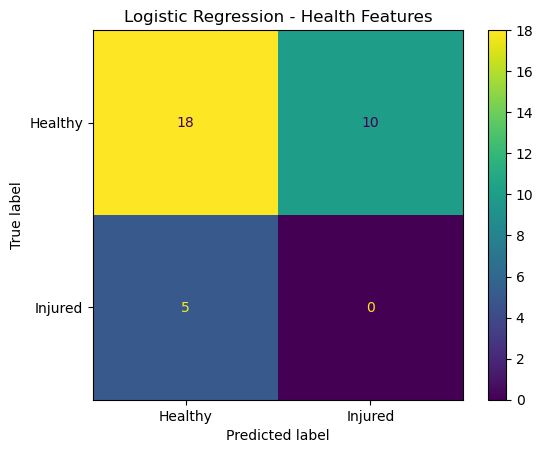

              precision    recall  f1-score   support

     Healthy       0.78      0.64      0.71        28
     Injured       0.00      0.00      0.00         5

    accuracy                           0.55        33
   macro avg       0.39      0.32      0.35        33
weighted avg       0.66      0.55      0.60        33



In [7]:
X_health = df[health_features]

logistic_health_results = run_logistic_regression(
    X_health,
    y,
    "Health Features"
)


Running Features - Logistic Regression
---------------------------------------------
accuracy: 0.610 +/- 0.146
balanced_accuracy: 0.360 +/- 0.089
precision: 0.000 +/- 0.000
recall: 0.000 +/- 0.000
f1: 0.000 +/- 0.000


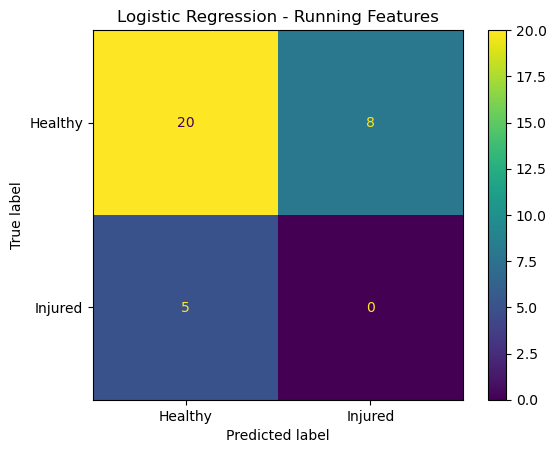

              precision    recall  f1-score   support

     Healthy       0.80      0.71      0.75        28
     Injured       0.00      0.00      0.00         5

    accuracy                           0.61        33
   macro avg       0.40      0.36      0.38        33
weighted avg       0.68      0.61      0.64        33



In [8]:
X_running = df[running_features]

logistic_running_results = run_logistic_regression(
    X_running,
    y,
    "Running Features"
)

In [9]:
# Create Logistic Regression model
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Cross-validated injury probabilities - Health
health_prob = cross_val_predict(
    logistic_model,
    X_health,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Cross-validated injury probabilities - Running
running_prob = cross_val_predict(
    logistic_model,
    X_running,
    y,
    cv=cv,
    method="predict_proba"
)[:, 1]

In [10]:
thresholds = np.arange(0.10, 0.55, 0.05)

health_threshold_results = []
running_threshold_results = []

for threshold in thresholds:

    # HEALTH
    health_pred = (health_prob >= threshold).astype(int)

    health_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y,
            health_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y,
            health_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y,
            health_pred,
            zero_division=0
        ),
        "Injuries Detected": ((health_pred == 1) & (y == 1)).sum(),
        "False Positives": ((health_pred == 1) & (y == 0)).sum()
    })

    # RUNNING
    running_pred = (running_prob >= threshold).astype(int)

    running_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y,
            running_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y,
            running_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y,
            running_pred,
            zero_division=0
        ),
        "Injuries Detected": ((running_pred == 1) & (y == 1)).sum(),
        "False Positives": ((running_pred == 1) & (y == 0)).sum()
    })

health_threshold_df = pd.DataFrame(
    health_threshold_results
)

running_threshold_df = pd.DataFrame(
    running_threshold_results
)

In [11]:
print("HEALTH FEATURES")
display(health_threshold_df)

HEALTH FEATURES


,Threshold,Precision,Recall,F1,Injuries Detected,False Positives
0,0.10,0.115385,0.6,0.193548,3,23
1,0.15,0.086957,0.4,0.142857,2,21
2,0.20,0.000000,0.0,0.000000,0,20
3,0.25,0.000000,0.0,0.000000,0,18
4,0.30,0.000000,0.0,0.000000,0,15
5,0.35,0.000000,0.0,0.000000,0,14
6,0.40,0.000000,0.0,0.000000,0,13
7,0.45,0.000000,0.0,0.000000,0,11
8,0.50,0.000000,0.0,0.000000,0,10


In [12]:
print("RUNNING FEATURES")
display(running_threshold_df)

RUNNING FEATURES


,Threshold,Precision,Recall,F1,Injuries Detected,False Positives
0,0.10,0.115385,0.6,0.193548,3,23
1,0.15,0.090909,0.4,0.148148,2,20
2,0.20,0.095238,0.4,0.153846,2,19
3,0.25,0.050000,0.2,0.080000,1,19
4,0.30,0.058824,0.2,0.090909,1,16
5,0.35,0.076923,0.2,0.111111,1,12
6,0.40,0.000000,0.0,0.000000,0,11
7,0.45,0.000000,0.0,0.000000,0,9
8,0.50,0.000000,0.0,0.000000,0,8


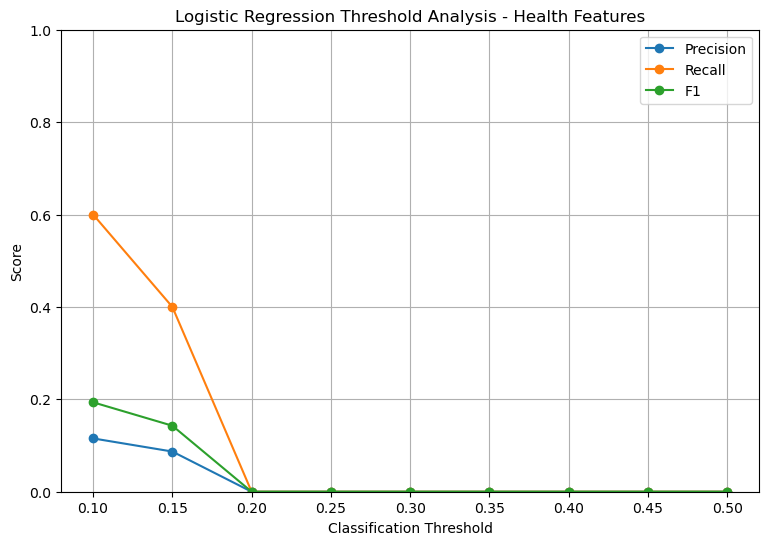

In [13]:
plt.figure(figsize=(9, 6))

plt.plot(
    health_threshold_df["Threshold"],
    health_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    health_threshold_df["Threshold"],
    health_threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    health_threshold_df["Threshold"],
    health_threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title(
    "Logistic Regression Threshold Analysis - Health Features"
)

plt.ylim(0, 1)
plt.legend()
plt.grid()

plt.show()

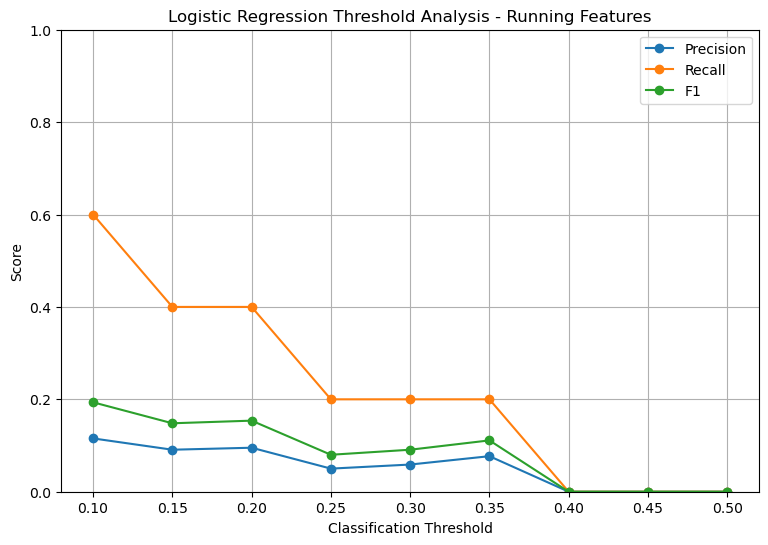

In [14]:
plt.figure(figsize=(9, 6))

plt.plot(
    running_threshold_df["Threshold"],
    running_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    running_threshold_df["Threshold"],
    running_threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    running_threshold_df["Threshold"],
    running_threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title(
    "Logistic Regression Threshold Analysis - Running Features"
)

plt.ylim(0, 1)
plt.legend()
plt.grid()

plt.show()

In [15]:
best_health = health_threshold_df.loc[
    health_threshold_df["F1"].idxmax()
]

best_running = running_threshold_df.loc[
    running_threshold_df["F1"].idxmax()
]

print("Best Health Threshold")
print(best_health)

print("\nBest Running Threshold")
print(best_running)

Best Health Threshold
Threshold             0.100000
Precision             0.115385
Recall                0.600000
F1                    0.193548
Injuries Detected     3.000000
False Positives      23.000000
Name: 0, dtype: float64

Best Running Threshold
Threshold             0.100000
Precision             0.115385
Recall                0.600000
F1                    0.193548
Injuries Detected     3.000000
False Positives      23.000000
Name: 0, dtype: float64


In [16]:
best_health_threshold = best_health["Threshold"]
best_running_threshold = best_running["Threshold"]

health_pred_adjusted = (
    health_prob >= best_health_threshold
).astype(int)

running_pred_adjusted = (
    running_prob >= best_running_threshold
).astype(int)

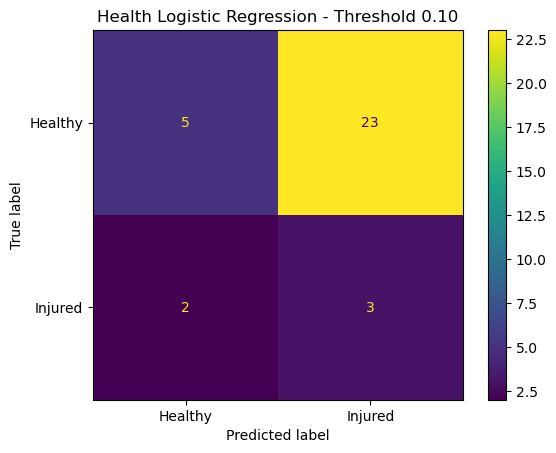

              precision    recall  f1-score   support

     Healthy       0.71      0.18      0.29        28
     Injured       0.12      0.60      0.19         5

    accuracy                           0.24        33
   macro avg       0.41      0.39      0.24        33
weighted avg       0.62      0.24      0.27        33



In [17]:
cm_health = confusion_matrix(
    y,
    health_pred_adjusted,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_health,
    display_labels=["Healthy", "Injured"]
)

disp.plot()

plt.title(
    f"Health Logistic Regression "
    f"- Threshold {best_health_threshold:.2f}"
)

plt.show()

print(
    classification_report(
        y,
        health_pred_adjusted,
        labels=[0, 1],
        target_names=["Healthy", "Injured"],
        zero_division=0
    )
)

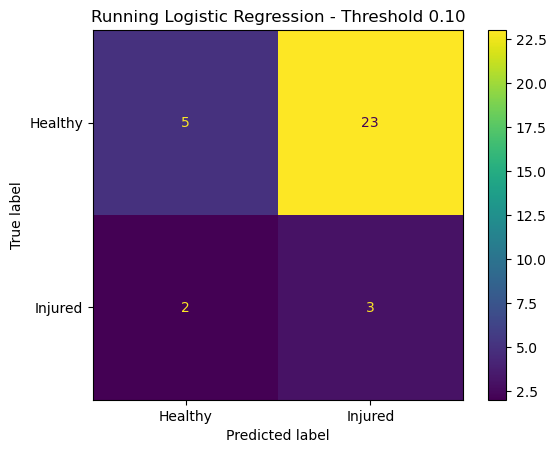

              precision    recall  f1-score   support

     Healthy       0.71      0.18      0.29        28
     Injured       0.12      0.60      0.19         5

    accuracy                           0.24        33
   macro avg       0.41      0.39      0.24        33
weighted avg       0.62      0.24      0.27        33



In [18]:
cm_running = confusion_matrix(
    y,
    running_pred_adjusted,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_running,
    display_labels=["Healthy", "Injured"]
)

disp.plot()

plt.title(
    f"Running Logistic Regression "
    f"- Threshold {best_running_threshold:.2f}"
)

plt.show()

print(
    classification_report(
        y,
        running_pred_adjusted,
        labels=[0, 1],
        target_names=["Healthy", "Injured"],
        zero_division=0
    )
)

In [19]:
comparison = pd.DataFrame({
    "Model": [
        "Health - Default 0.50",
        "Health - Adjusted",
        "Running - Default 0.50",
        "Running - Adjusted"
    ],

    "Threshold": [
        0.50,
        best_health_threshold,
        0.50,
        best_running_threshold
    ],

    "Injury Precision": [
        precision_score(
            y,
            (health_prob >= 0.50).astype(int),
            zero_division=0
        ),

        precision_score(
            y,
            health_pred_adjusted,
            zero_division=0
        ),

        precision_score(
            y,
            (running_prob >= 0.50).astype(int),
            zero_division=0
        ),

        precision_score(
            y,
            running_pred_adjusted,
            zero_division=0
        )
    ],

    "Injury Recall": [
        recall_score(
            y,
            (health_prob >= 0.50).astype(int),
            zero_division=0
        ),

        recall_score(
            y,
            health_pred_adjusted,
            zero_division=0
        ),

        recall_score(
            y,
            (running_prob >= 0.50).astype(int),
            zero_division=0
        ),

        recall_score(
            y,
            running_pred_adjusted,
            zero_division=0
        )
    ],

    "Injury F1": [
        f1_score(
            y,
            (health_prob >= 0.50).astype(int),
            zero_division=0
        ),

        f1_score(
            y,
            health_pred_adjusted,
            zero_division=0
        ),

        f1_score(
            y,
            (running_prob >= 0.50).astype(int),
            zero_division=0
        ),

        f1_score(
            y,
            running_pred_adjusted,
            zero_division=0
        )
    ]
})

display(comparison.round(3))

,Model,Threshold,Injury Precision,Injury Recall,Injury F1
0,Health - Default 0.50,0.5,0.000,0.0,0.000
1,Health - Adjusted,0.1,0.115,0.6,0.194
2,Running - Default 0.50,0.5,0.000,0.0,0.000
3,Running - Adjusted,0.1,0.115,0.6,0.194
